# Week 1: Sine waves and FFT

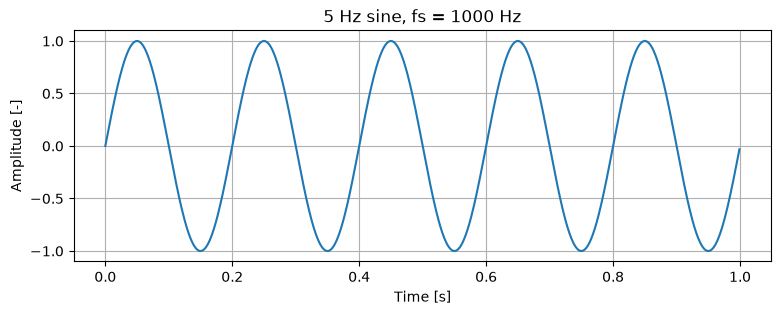

1000 samples


In [1]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000                      # sampling rate [Hz]
t = np.arange(0, 1, 1/fs)      # 1 s = 1000 samples

x5 = np.sin(2*np.pi*5*t)
plt.figure(figsize=(9, 3))
plt.plot(t, x5)
plt.title("5 Hz sine, fs = 1000 Hz")
plt.xlabel("Time [s]"); plt.ylabel("Amplitude [-]"); plt.grid(True)
plt.show()
print(len(t), "samples")

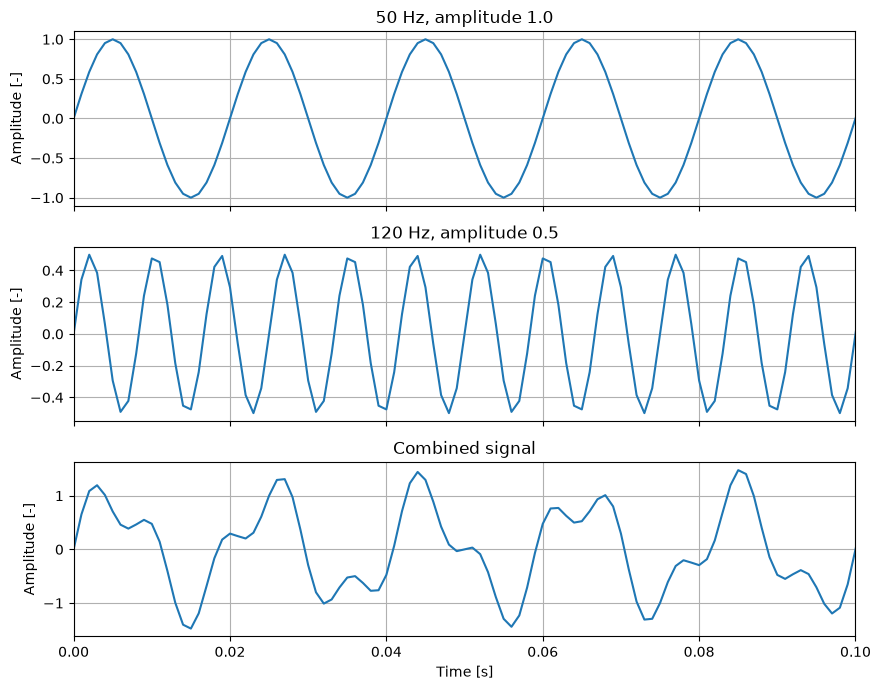

In [2]:
x50  = 1.0 * np.sin(2*np.pi*50*t)
x120 = 0.5 * np.sin(2*np.pi*120*t)
x = x50 + x120

fig, ax = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
ax[0].plot(t, x50);  ax[0].set_title("50 Hz, amplitude 1.0")
ax[1].plot(t, x120); ax[1].set_title("120 Hz, amplitude 0.5")
ax[2].plot(t, x);    ax[2].set_title("Combined signal")
for a in ax:
    a.set_ylabel("Amplitude [-]"); a.grid(True)
ax[2].set_xlabel("Time [s]"); ax[2].set_xlim(0, 0.1)
plt.tight_layout(); plt.show()

The combined signals looks messy and this is because of wave superposition, each signal has different frequency, amplitude and are out of phase with each other.


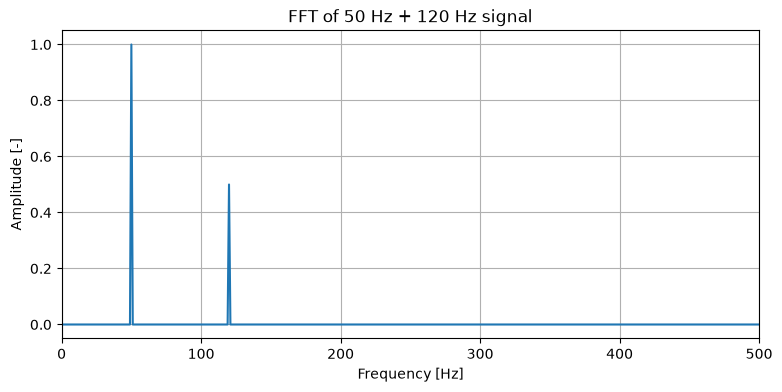

Peaks: [np.float64(50.0), np.float64(120.0)]


In [3]:
from scipy.fft import rfft, rfftfreq

N = len(x)
amp = np.abs(rfft(x)) * 2 / N
freqs = rfftfreq(N, 1/fs)

plt.figure(figsize=(9, 4))
plt.plot(freqs, amp)
plt.title("FFT of 50 Hz + 120 Hz signal")
plt.xlabel("Frequency [Hz]"); plt.ylabel("Amplitude [-]")
plt.xlim(0, 500); plt.grid(True); plt.show()
print("Peaks:", sorted(freqs[np.argsort(amp)[-2:]]))

FFT rewrites the signal from valur over time into how much of each signal is there. Peaks sit at 50 nd 120 Hz because those are the frequencies I chose and then the amplitudes are 1.0 and 0.5

In [4]:
x700 = np.sin(2*np.pi*700*t)
a700 = np.abs(rfft(x700)) * 2 / N
print("700 Hz tone shows up at", freqs[np.argmax(a700)], "Hz")

700 Hz tone shows up at 300.0 Hz
